**Purpose:** Imports libraries for binary morphology and image visualization.

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

**Purpose:** Defines erosion using a structuring element.

In [18]:
def erosion(img,kernel):
    result = np.zeros_like(img)
    
    rows,cols = img.shape
    kr , kc = kernel.shape
    
    pad_x =kr//2
    pad_y = kc//2
    
    for i in range(pad_x,rows-pad_x):
        for j in range(pad_y,cols- pad_y):
            region = img[i-pad_x:i+pad_x+1, j-pad_y:j+pad_y+1]
            
            if np.all(region[kernel==1] == 255):
                result[i][j] = 255
                
    return result
                

**Purpose:** Defines dilation using a structuring element.

In [19]:
def dilation (img,kernel):
    result = np.zeros_like(img)
    rows, cols = img.shape
    kr, kc = kernel.shape
    
    pad_x = kr//2
    pad_y = kc//2
    
    for i in range(pad_x, rows-pad_x):
        for j in range(pad_y,cols-pad_y):
            region = img[i-pad_x:i+pad_x+1,j-pad_y:j+pad_y+1]
            
            if np.any(region[kernel==1] == 255):
                result[i,j] = 255
    
    return result

**Purpose:** Defines opening as erosion followed by dilation.

In [20]:
def opening(img,kernel):
    erased = erosion(img,kernel)
    opened = dilation(erased,kernel)
    return opened

**Purpose:** Defines closing as dilation followed by erosion.

In [21]:
def closing(img,kernel):
    diluted = dilation(img,kernel)
    closed = erosion(diluted,kernel)
    
    return closed

**Purpose:** Binarizes the cat image, applies four morphological operations, and displays the results.

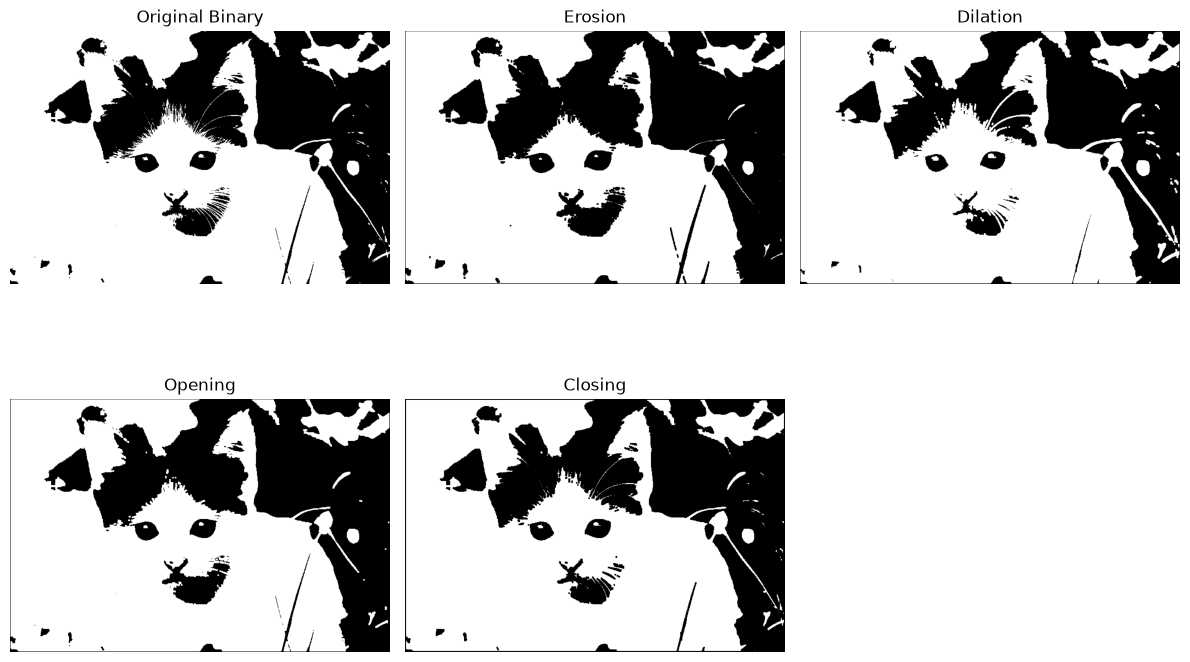

In [22]:
img = cv2.imread("../cat.jpg", 0)

if img is None:
    print("Image not found!")
    exit()

# Convert grayscale image into binary image
threshold = 127
binary = np.where(img >= threshold, 255, 0).astype(np.uint8)

# Define 3x3 structuring element
kernel = np.ones((3, 3), dtype=np.uint8)

# Apply morphological operations
eroded = erosion(binary, kernel)
dilated = dilation(binary, kernel)
opened = opening(binary, kernel)
closed = closing(binary, kernel)


# Display results
plt.figure(figsize=(12, 8))

images = [
    binary, eroded, dilated, opened, closed
]

titles = [
    "Original Binary",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing"
]

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Purpose:** This cell is intentionally left blank.